In [1]:
%pip install qiskit qiskit-aer matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [22]:
%pip install matplotlib qiskit qiskit-aer

Note: you may need to restart the kernel to use updated packages.


In [23]:
%matplotlib inline

import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

In [6]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display, Markdown
import pandas as pd
import matplotlib.pyplot as plt

## 1. Create a Single-Qubit Quantum Circuit

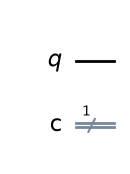

In [7]:
display(Markdown("## 1. Create a Single-Qubit Quantum Circuit"))

qc = QuantumCircuit(1, 1)

display(qc.draw(output="mpl"))

## 2. Initial State: |0>

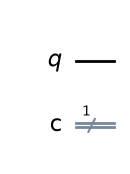

The qubit starts in the initial state |0>.


In [8]:
display(Markdown("## 2. Initial State: |0>"))

initial_circuit = QuantumCircuit(1, 1)

display(initial_circuit.draw(output="mpl"))

print("The qubit starts in the initial state |0>.")

## 3(a). Circuit A: One X Gate

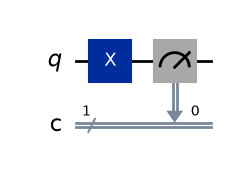

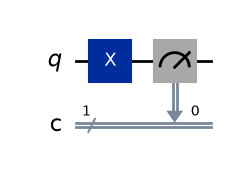

In [30]:
display(Markdown("## 3(a). Circuit A: One X Gate"))

circuit_A = QuantumCircuit(1, 1)
circuit_A.x(0)
circuit_A.measure(0, 0)

display(circuit_A.draw(output="mpl"))

## 3(b). Circuit B: Two X Gates

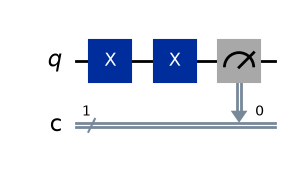

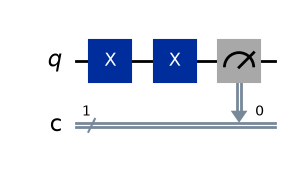

In [29]:
display(Markdown("## 3(b). Circuit B: Two X Gates"))

circuit_B = QuantumCircuit(1, 1)
circuit_B.x(0)
circuit_B.x(0)
circuit_B.measure(0, 0)

display(circuit_B.draw(output="mpl"))

## 3(c). Circuit C: One H Gate

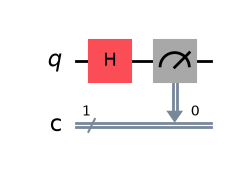

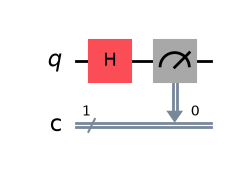

In [28]:
display(Markdown("## 3(c). Circuit C: One H Gate"))

circuit_C = QuantumCircuit(1, 1)
circuit_C.h(0)
circuit_C.measure(0, 0)

display(circuit_C.draw(output="mpl"))

In [27]:
predictions = {
    "Circuit A": "100 outcomes of 1",
    "Circuit B": "100 outcomes of 0",
    "Circuit C": "Approximately 50 outcomes of 0 and 50 outcomes of 1"
}

display(Markdown("## 4. Predictions Before Execution"))

for name, prediction in predictions.items():
    print(name + ": " + prediction)

## 4. Predictions Before Execution

Circuit A: 100 outcomes of 1
Circuit B: 100 outcomes of 0
Circuit C: Approximately 50 outcomes of 0 and 50 outcomes of 1


In [16]:
display(Markdown("## 5. Execute Each Circuit for 100 Shots"))

simulator = AerSimulator()

circuits = {
    "Circuit A": circuit_A,
    "Circuit B": circuit_B,
    "Circuit C": circuit_C
}

results = {}

for name, circuit in circuits.items():
    job = simulator.run(circuit, shots=100)
    result = job.result()
    counts = result.get_counts()

    results[name] = counts

    print(name, ":", counts)

## 5. Execute Each Circuit for 100 Shots

Circuit A : {'1': 100}
Circuit B : {'0': 100}
Circuit C : {'0': 52, '1': 48}


In [17]:
display(Markdown("## 6. Measurement Results"))

results_table = pd.DataFrame([
    {
        "Circuit": name,
        "Shots": 100,
        "Count of 0": counts.get("0", 0),
        "Count of 1": counts.get("1", 0)
    }
    for name, counts in results.items()
])

display(results_table)

## 6. Measurement Results

,Circuit,Shots,Count of 0,Count of 1
0,Circuit A,100,0,100
1,Circuit B,100,100,0
2,Circuit C,100,52,48


In [18]:
display(Markdown("## 7. Prediction vs Actual Results"))

for name in circuits:
    print(name)
    print("Prediction:", predictions[name])
    print("Actual measurement counts:", results[name])
    print()

## 7. Prediction vs Actual Results

Circuit A
Prediction: 100 outcomes of 1
Actual measurement counts: {'1': 100}

Circuit B
Prediction: 100 outcomes of 0
Actual measurement counts: {'0': 100}

Circuit C
Prediction: Approximately 50 outcomes of 0 and 50 outcomes of 1
Actual measurement counts: {'0': 52, '1': 48}



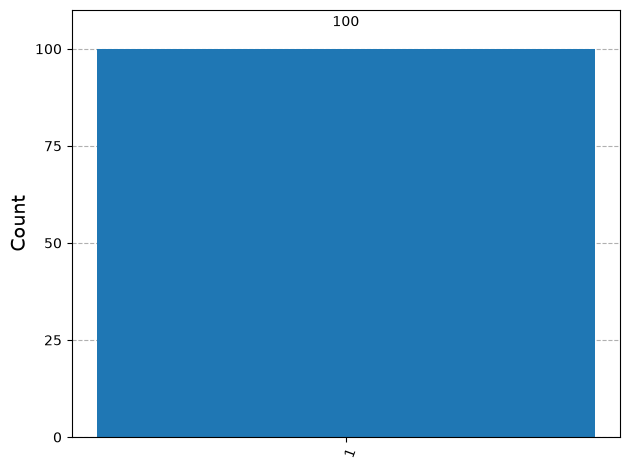

In [24]:
# Histogram for Circuit A
plot_histogram(results["Circuit A"])
plt.show()

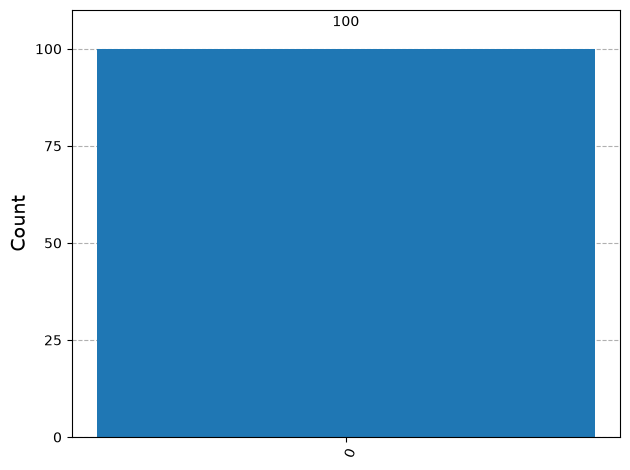

In [25]:
# Histogram for Circuit B
plot_histogram(results["Circuit B"])
plt.show()

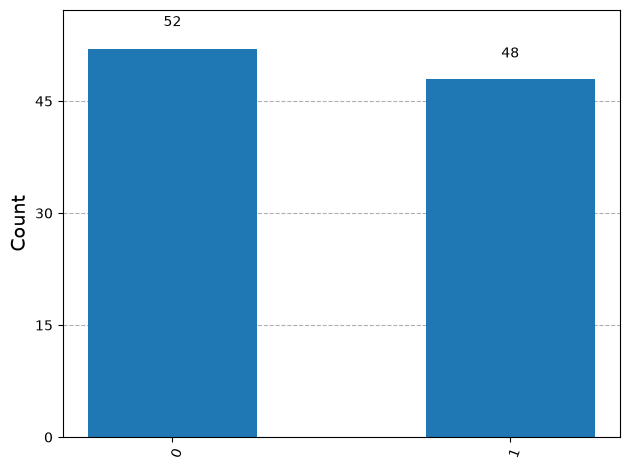

In [26]:
# Histogram for Circuit C
plot_histogram(results["Circuit C"])
plt.show()

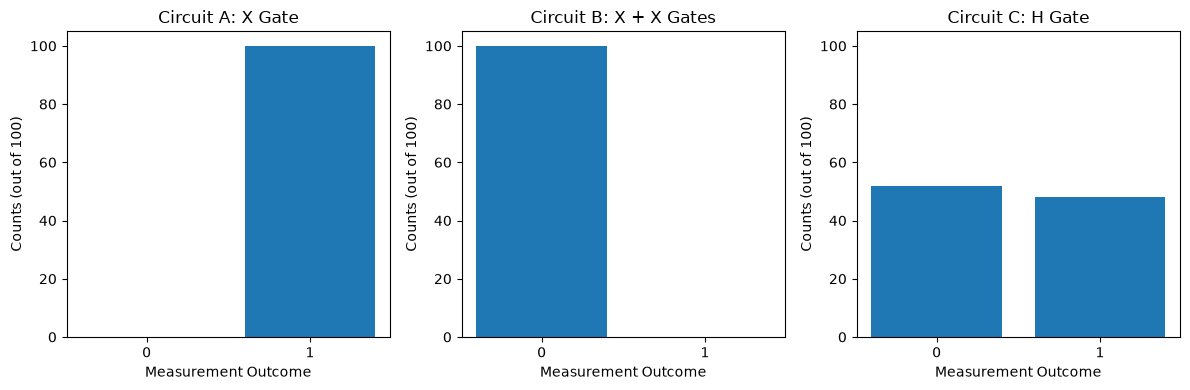

In [31]:
import matplotlib.pyplot as plt

# Measurement results from the three circuits
results_A = results["Circuit A"]
results_B = results["Circuit B"]
results_C = results["Circuit C"]

# Create one graph with three histograms side by side
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, counts, title in zip(
    axes,
    [results_A, results_B, results_C],
    ["Circuit A: X Gate", "Circuit B: X + X Gates", "Circuit C: H Gate"]
):
    outcomes = ["0", "1"]
    values = [counts.get(bit, 0) for bit in outcomes]

    ax.bar(outcomes, values)
    ax.set_title(title)
    ax.set_xlabel("Measurement Outcome")
    ax.set_ylabel("Counts (out of 100)")
    ax.set_ylim(0, 105)
    ax.set_xticks([0, 1], ["0", "1"])

plt.tight_layout()
plt.show()